# 模块B：智能制造与工业质检（30分）

基于 NEU-DET 钢材表面缺陷数据集，完成 **数据集构建 → 数据增强 → CNN分类 → U-Net分割 → 推理可视化 → 混淆矩阵分析 → 质检报告生成** 全流程。

| 任务 | 内容 | 分值 |
| --- | --- | --- |
| B0 | 数据自检与演示数据生成 | - |
| B1 | 数据集加载与类别分布统计 | 3 |
| B2 | 标注格式解析与数据集构建 | 3 |
| B3 | 数据增强流水线实现 | 3 |
| B4 | 自定义CNN分类模型构建 | 3 |
| B5 | CNN模型编译与训练 | 3 |
| B6 | U-Net分割模型构建 | 3 |
| B7 | 模型推理与检测结果可视化 | 4 |
| B8 | 混淆矩阵分析与模型优化 | 4 |
| B9 | 工业质检报告生成 | 4 |

> 使用方法：从上到下按顺序运行；每个任务的库在各自 cell 内单独导入，方便单独记忆与复习。
>
> **提示**：没有数据集时先运行 B0，会自动生成演示数据，保证后续任务全部可运行。

## B0 数据自检与演示数据生成
**做什么**：检测 `data/NEU-DET/` 是否存在数据；没有则自动生成 6 类缺陷演示图 + VOC 格式 XML 标注，供后续任务练习使用。

**记忆点**：比赛时把赛题数据集解压到该目录，本 cell 会自动跳过生成。

In [ ]:
# ===== B0：数据自检,缺数据则自动生成演示数据 =====
import os
import numpy as np
import cv2

IMG_DIR = 'data/NEU-DET/images'
ANN_DIR = 'data/NEU-DET/annotations'
CLASSES = ['crazing', 'inclusion', 'patches', 'pitted', 'rolled', 'scratches']
N_PER_CLASS = 10                     # 演示数据每类10张
# TODO: 如果我要修改类别个数或者样本个数，不可跳过生成


# TODO: 仅判断 images 非空就跳过，未校验 annotations 目录，XML 缺失会导致 B2 报错
if os.path.isdir(IMG_DIR) and len(os.listdir(IMG_DIR)) > 0:
    print('检测到真实数据集, 跳过生成')
else:
    os.makedirs(IMG_DIR, exist_ok=True)
    os.makedirs(ANN_DIR, exist_ok=True)
    rng = np.random.default_rng(42)
    xml_tpl = ('<annotation><filename>{f}</filename><size><width>200</width>'
               '<height>200</height></size><object><name>{c}</name><bndbox>'
               '<xmin>{x1}</xmin><ymin>{y1}</ymin><xmax>{x2}</xmax>'
               '<ymax>{y2}</ymax></bndbox></object></annotation>')
    for c in CLASSES:
        for i in range(N_PER_CLASS):
            img = rng.integers(100, 156, (200, 200, 3), dtype=np.uint8)  # 灰底噪声
            x1, y1 = rng.integers(20, 120, 2)
            x2, y2 = x1 + rng.integers(20, 60), y1 + rng.integers(20, 60)
            cv2.rectangle(img, (int(x1), int(y1)), (int(x2), int(y2)),
                          (0, 0, 220), -1)                               # 模拟缺陷块
            fname = f'{c}_{i}.jpg'
            cv2.imwrite(os.path.join(IMG_DIR, fname), img)
            with open(os.path.join(ANN_DIR, fname.replace('.jpg', '.xml')),
                      'w', encoding='utf-8') as f:
                f.write(xml_tpl.format(f=fname, c=c, x1=x1, y1=y1, x2=x2, y2=y2))
    print(f'演示数据已生成: {len(CLASSES) * N_PER_CLASS} 张图像 + 对应XML标注')

检测到真实数据集, 跳过生成


## B1 数据集加载与类别分布统计（3分）
**做什么**：遍历图像文件夹 → 读图存入列表 → 从文件名提取类别 → Counter统计 → 画条形图。

**记忆点**：`os.listdir` 遍历、`cv2.imread` 读图、`collections.Counter` 计数、`plt.bar` 画图。

共加载 60 张图像, 示例尺寸: (200, 200, 3)
Counter({'crazing': 10, 'inclusion': 10, 'patches': 10, 'pitted': 10, 'rolled': 10, 'scratches': 10})


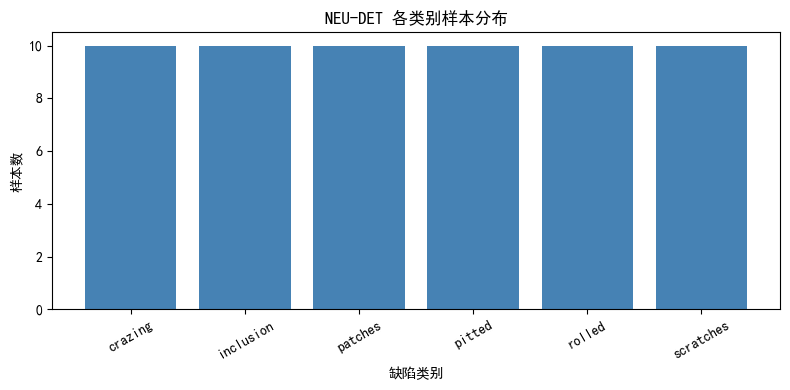

In [12]:
# ===== B1：数据集加载与类别分布统计 =====
import os
import cv2
import collections
import matplotlib.pyplot as plt

plt.rcParams['font.sans-serif'] = ['SimHei']   # 中文正常显示
plt.rcParams['axes.unicode_minus'] = False

IMG_DIR = 'data/NEU-DET/images'                # 钢材缺陷图像文件夹

# 1. 遍历文件夹,读取全部图像存入列表
files = sorted(os.listdir(IMG_DIR))
images = [cv2.imread(os.path.join(IMG_DIR, f)) for f in files]
# TODO: 空目录时 images[0] 会报 IndexError，cv2.imread 失败返回 None 也未处理
print(f'共加载 {len(images)} 张图像, 示例尺寸: {images[0].shape}')

# 2. 文件名形如 crazing_1.jpg, 下划线前即为缺陷类别
labels = [f.split('_')[0] for f in files]

# 3. Counter统计各类别数量
counter = collections.Counter(labels)
print(counter)

# 4. 条形图展示类别分布
plt.figure(figsize=(8, 4))
plt.bar(counter.keys(), counter.values(), color='steelblue')
plt.title('NEU-DET 各类别样本分布')
plt.xlabel('缺陷类别')
plt.ylabel('样本数')
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

## B2 标注格式解析与数据集构建（3分）
**做什么**：解析 PASCAL VOC 的 XML 标注 → VOC坐标(xmin,ymin,xmax,ymax) 转 YOLO归一化中心坐标 → 构建 DataFrame → 划分训练/验证集。

**记忆点**：`ET.parse` 解析XML、`root.find/findall` 取节点、`train_test_split` 划分。

In [13]:
# ===== B2：VOC标注解析与数据集构建 =====
import os
import glob
import xml.etree.ElementTree as ET
import pandas as pd
from sklearn.model_selection import train_test_split

IMG_DIR = 'data/NEU-DET/images'
ANN_DIR = 'data/NEU-DET/annotations'            # XML标注文件夹

# 1. 解析单个XML -> [文件名,宽,高,类别,xmin,ymin,xmax,ymax]
def parse_voc(xml_path):
    root = ET.parse(xml_path).getroot()
    fname = root.find('filename').text
    w = int(root.find('size/width').text)
    h = int(root.find('size/height').text)
    rows = []
    for obj in root.findall('object'):
        cls = obj.find('name').text
        b = obj.find('bndbox')
        rows.append([fname, w, h, cls,
                     int(b.find('xmin').text), int(b.find('ymin').text),
                     int(b.find('xmax').text), int(b.find('ymax').text)])
    return rows

# 2. 解析全部XML,构建DataFrame
all_rows = []
for xp in glob.glob(os.path.join(ANN_DIR, '*.xml')):
    all_rows.extend(parse_voc(xp))
cols = ['filename', 'width', 'height', 'class', 'xmin', 'ymin', 'xmax', 'ymax']
df = pd.DataFrame(all_rows, columns=cols)

# 3. VOC框 -> YOLO格式(归一化 中心x,中心y,宽,高)
df['cx'] = (df.xmin + df.xmax) / 2 / df.width
df['cy'] = (df.ymin + df.ymax) / 2 / df.height
df['bw'] = (df.xmax - df.xmin) / df.width
df['bh'] = (df.ymax - df.ymin) / df.height
df['img_path'] = df['filename'].apply(lambda f: os.path.join(IMG_DIR, f))

# 4. 按图像名划分训练/验证集(8:2, 按类别分层抽样,保证每类都有验证样本)
img_cls = df.drop_duplicates('filename').set_index('filename')['class']
imgs = img_cls.index.to_numpy()
# TODO: stratify 分层抽样要求每类至少 2 个样本，某类只有 1 张会报错
tr, va = train_test_split(imgs, test_size=0.2, random_state=42,
                          stratify=img_cls.values)
train_df = df[df.filename.isin(tr)].reset_index(drop=True)
val_df   = df[df.filename.isin(va)].reset_index(drop=True)
print(f'训练集 {len(tr)} 张, 验证集 {len(va)} 张')
train_df.head()

训练集 48 张, 验证集 12 张


,filename,width,height,class,xmin,ymin,xmax,ymax,cx,cy,bw,bh,img_path
0,crazing_0.jpg,200,200,crazing,100,107,146,130,0.6150,0.5925,0.230,0.115,data/NEU-DET/images\crazing_0.jpg
1,crazing_1.jpg,200,200,crazing,26,49,79,84,0.2625,0.3325,0.265,0.175,data/NEU-DET/images\crazing_1.jpg
2,crazing_2.jpg,200,200,crazing,71,84,106,133,0.4425,0.5425,0.175,0.245,data/NEU-DET/images\crazing_2.jpg
3,crazing_4.jpg,200,200,crazing,34,93,80,125,0.2850,0.5450,0.230,0.160,data/NEU-DET/images\crazing_4.jpg
4,crazing_5.jpg,200,200,crazing,76,34,113,80,0.4725,0.2850,0.185,0.230,data/NEU-DET/images\crazing_5.jpg


## B3 数据增强流水线实现（3分）
**做什么**：按赛题参数定义 `ImageDataGenerator` 增强器 → 用 `flow_from_dataframe` 接 B2 的 DataFrame → 可视化5张增强样本。

**记忆点**：旋转30、平移0.2、水平翻转、亮度0.8~1.2；`rescale=1/255` 顺便做归一化。

Found 48 validated image filenames belonging to 6 classes.
Found 12 validated image filenames belonging to 6 classes.
类别表: ['crazing', 'inclusion', 'patches', 'pitted', 'rolled', 'scratches']


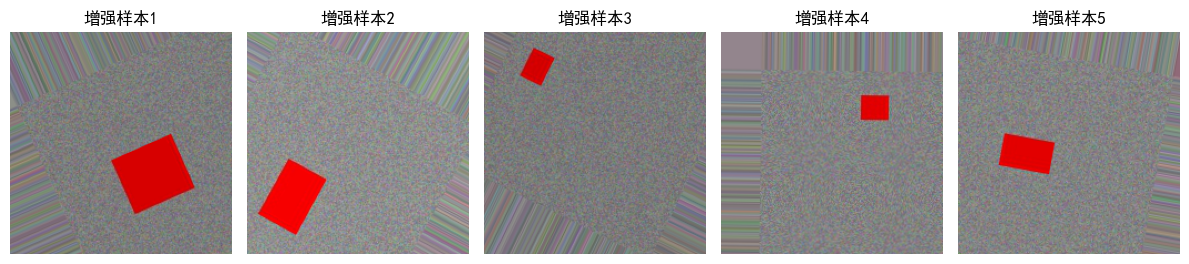

In [ ]:
# ===== B3：数据增强流水线 =====
import matplotlib.pyplot as plt
from tensorflow.keras.preprocessing.image import ImageDataGenerator

IMG_SIZE = (200, 200)

# 1. 训练增强器(赛题规定参数 + 归一化)
datagen = ImageDataGenerator(
    rescale=1. / 255,
    rotation_range=30,           # 随机旋转±30°
    width_shift_range=0.2,       # 水平平移20%
    height_shift_range=0.2,      # 垂直平移20%
    horizontal_flip=True,        # 随机水平翻转
    brightness_range=(0.8, 1.2)  # 亮度抖动
)
val_datagen = ImageDataGenerator(rescale=1. / 255)   # 验证集只归一化

# 2. 从B2的DataFrame生成图像批次
train_gen = datagen.flow_from_dataframe(
    train_df, x_col='img_path', y_col='class',
    target_size=IMG_SIZE, batch_size=32, class_mode='categorical')
val_gen = val_datagen.flow_from_dataframe(
    val_df, x_col='img_path', y_col='class',
    target_size=IMG_SIZE, batch_size=32, class_mode='categorical', shuffle=False)

CLASS_NAMES = list(train_gen.class_indices.keys())
print('类别表:', CLASS_NAMES)
# TODO: 增强后的数据集保存起来，以便后续使用

# 3. 取一个批次,可视化5张增强样本
x_batch, y_batch = next(train_gen)
plt.figure(figsize=(12, 3))
for i in range(5):
    plt.subplot(1, 5, i + 1)
    plt.imshow(x_batch[i])
    plt.title(f'增强样本{i+1}')
    plt.axis('off')
plt.tight_layout()
plt.show()

## B4 自定义CNN分类模型构建（3分）
**做什么**：Sequential 顺序堆叠：Conv(32) → Pool → Conv(64) → Pool → Flatten → Dense(128) → Dropout(0.5) → Dense(softmax)。

**记忆点**：卷积提特征、池化降尺寸、Dropout防过拟合、最后softmax输出类别数。

In [5]:
# ===== B4：自定义CNN分类模型 =====
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Conv2D, MaxPooling2D, Flatten, Dense, Dropout

NUM_CLASSES = len(CLASS_NAMES)   # NEU-DET 共6类

model = Sequential([
    Conv2D(32, (3, 3), activation='relu', input_shape=(*IMG_SIZE, 3)),
    MaxPooling2D((2, 2)),
    Conv2D(64, (3, 3), activation='relu'),
    MaxPooling2D((2, 2)),
    Flatten(),
    Dense(128, activation='relu'),
    Dropout(0.5),
    Dense(NUM_CLASSES, activation='softmax')
])
model.summary()

C:\Users\linzi\AppData\Roaming\Python\Python312\site-packages\keras\src\layers\convolutional\base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                      │ (None, 198, 198, 32)        │             896 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d (MaxPooling2D)         │ (None, 99, 99, 32)          │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d_1 (Conv2D)                    │ (None, 97, 97, 64)          │          18,496 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d_1 (MaxPooling2D)       │ (None, 48, 48, 64)          │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ flatten (Flatten)                    │ (None, 147456)              │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense (Dense)                        │ (None, 128)                 │      18,874,496 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout (Dropout)                    │ (None, 128)                 │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_1 (Dense)                      │ (None, 6)                   │             774 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 18,894,662 (72.08 MB)

 Trainable params: 18,894,662 (72.08 MB)

 Non-trainable params: 0 (0.00 B)

## B5 CNN模型编译与训练（3分）
**做什么**：compile(Adam + 交叉熵 + accuracy) → fit(epochs=30, batch_size=32, 验证集, 早停) → 保存模型。

**记忆点**：`EarlyStopping(monitor='val_loss', patience=5)` 验证损失5轮不降就停。

In [6]:
# ===== B5：CNN模型编译与训练 =====
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.callbacks import EarlyStopping

# 1. 编译:Adam(0.001) + 多分类交叉熵 + 准确率
model.compile(optimizer=Adam(learning_rate=0.001),
              loss='categorical_crossentropy',
              metrics=['accuracy'])

# 2. 早停回调:验证损失5轮不改善则停止并回滚到最优权重
early_stop = EarlyStopping(monitor='val_loss', patience=5,
                           restore_best_weights=True)

# 3. 训练(生成器已含batch_size=32,fit里不要再传)
history = model.fit(
    train_gen,
    epochs=30,
    validation_data=val_gen,
    callbacks=[early_stop]
)

# 4. 保存模型,供B7/B8加载
# TODO: 模型固定保存为 cnn_neu.h5，重跑会覆盖，建议加时间戳或先判断已存在
model.save('cnn_neu.h5')
print('模型已保存为 cnn_neu.h5')

Epoch 1/30
2/2 ━━━━━━━━━━━━━━━━━━━━ 3s 851ms/step - accuracy: 0.1875 - loss: 10.0195 - val_accuracy: 0.1667 - val_loss: 8.2257
Epoch 2/30
2/2 ━━━━━━━━━━━━━━━━━━━━ 1s 340ms/step - accuracy: 0.1042 - loss: 9.8973 - val_accuracy: 0.1667 - val_loss: 4.0885
Epoch 3/30
2/2 ━━━━━━━━━━━━━━━━━━━━ 1s 637ms/step - accuracy: 0.1667 - loss: 3.5066 - val_accuracy: 0.2500 - val_loss: 1.9931
Epoch 4/30
2/2 ━━━━━━━━━━━━━━━━━━━━ 1s 337ms/step - accuracy: 0.1667 - loss: 2.1792 - val_accuracy: 0.1667 - val_loss: 1.8670
Epoch 5/30
2/2 ━━━━━━━━━━━━━━━━━━━━ 1s 675ms/step - accuracy: 0.1667 - loss: 1.8484 - val_accuracy: 0.0833 - val_loss: 1.8103
Epoch 6/30
2/2 ━━━━━━━━━━━━━━━━━━━━ 1s 363ms/step - accuracy: 0.1875 - loss: 1.8059 - val_accuracy: 0.0833 - val_loss: 1.7982
Epoch 7/30
2/2 ━━━━━━━━━━━━━━━━━━━━ 1s 670ms/step - accuracy: 0.1042 - loss: 1.7985 - val_accuracy: 0.0833 - val_loss: 1.7917
Epoch 8/30
2/2 ━━━━━━━━━━━━━━━━━━━━ 1s 301ms/step - accuracy: 0.1250 - loss: 1.7904 - val_accuracy: 0.0833 - val_loss

模型已保存为 cnn_neu.h5


## B6 U-Net分割模型构建（3分）
**做什么**：编码器(卷积+池化下采样) → 瓶颈层 → 解码器(转置卷积上采样 + 跳跃连接拼接) → 1×1卷积+sigmoid输出掩膜。

**记忆点**：U-Net = 下采样3次 + 上采样3次 + 同层 `concatenate` 拼接(跳跃连接)。

In [7]:
# ===== B6：U-Net分割模型 =====
from tensorflow.keras.models import Model
from tensorflow.keras.layers import (Input, Conv2D, MaxPooling2D,
                                     Conv2DTranspose, concatenate)

def conv_block(x, filters):
    x = Conv2D(filters, 3, activation='relu', padding='same')(x)
    x = Conv2D(filters, 3, activation='relu', padding='same')(x)
    return x

inputs = Input((128, 128, 3))
# TODO: U-Net 输入 128x128 与分类的 IMG_SIZE=200x200 不一致，推理需 resize

# 编码器:逐层下采样, c1/c2/c3 留作跳跃连接
c1 = conv_block(inputs, 32);  p1 = MaxPooling2D()(c1)
c2 = conv_block(p1, 64);      p2 = MaxPooling2D()(c2)
c3 = conv_block(p2, 128);     p3 = MaxPooling2D()(c3)

# 瓶颈层
bn = conv_block(p3, 256)

# 解码器:上采样 -> 拼对应编码层 -> 卷积
u1 = Conv2DTranspose(128, 2, strides=2, padding='same')(bn)
d1 = conv_block(concatenate([u1, c3]), 128)
u2 = Conv2DTranspose(64, 2, strides=2, padding='same')(d1)
d2 = conv_block(concatenate([u2, c2]), 64)
u3 = Conv2DTranspose(32, 2, strides=2, padding='same')(d2)
d3 = conv_block(concatenate([u3, c1]), 32)

# 输出层:1x1卷积 + sigmoid -> 单通道缺陷掩膜
outputs = Conv2D(1, 1, activation='sigmoid')(d3)

unet = Model(inputs, outputs)
unet.summary()   # 看到 concatenate 层即跳跃连接正确

Model: "functional_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                  ┃ Output Shape              ┃         Param # ┃ Connected to               ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━┩
│ input_layer_1 (InputLayer)    │ (None, 128, 128, 3)       │               0 │ -                          │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ conv2d_2 (Conv2D)             │ (None, 128, 128, 32)      │             896 │ input_layer_1[0][0]        │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ conv2d_3 (Conv2D)             │ (None, 128, 128, 32)      │           9,248 │ conv2d_2[0][0]             │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ max_pooling2d_2               │ (None, 64, 64, 32)        │               0 │ conv2d_3[0][0]             │
│ (MaxPooling2D)                │                           │                 │                            │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ conv2d_4 (Conv2D)             │ (None, 64, 64, 64)        │          18,496 │ max_pooling2d_2[0][0]      │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ conv2d_5 (Conv2D)             │ (None, 64, 64, 64)        │          36,928 │ conv2d_4[0][0]             │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ max_pooling2d_3               │ (None, 32, 32, 64)        │               0 │ conv2d_5[0][0]             │
│ (MaxPooling2D)                │                           │                 │                            │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ conv2d_6 (Conv2D)             │ (None, 32, 32, 128)       │          73,856 │ max_pooling2d_3[0][0]      │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ conv2d_7 (Conv2D)             │ (None, 32, 32, 128)       │         147,584 │ conv2d_6[0][0]             │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ max_pooling2d_4               │ (None, 16, 16, 128)       │               0 │ conv2d_7[0][0]             │
│ (MaxPooling2D)                │                           │                 │                            │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ conv2d_8 (Conv2D)             │ (None, 16, 16, 256)       │         295,168 │ max_pooling2d_4[0][0]      │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ conv2d_9 (Conv2D)             │ (None, 16, 16, 256)       │         590,080 │ conv2d_8[0][0]             │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ conv2d_transpose              │ (None, 32, 32, 128)       │         131,200 │ conv2d_9[0][0]             │
│ (Conv2DTranspose)             │                           │                 │                            │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ concatenate (Concatenate)     │ (None, 32, 32, 256)       │               0 │ conv2d_transpose[0][0],    │
│                               │                           │                 │ conv2d_7[0][0]             │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ conv2d_10 (Conv2D)            │ (None, 32, 32, 128)       │         295,04

 Total params: 1,925,601 (7.35 MB)

 Trainable params: 1,925,601 (7.35 MB)

 Non-trainable params: 0 (0.00 B)

## B7 模型推理与检测结果可视化（4分）
**做什么**：加载模型 → 预处理(缩放+归一化) → predict → 分类取 `argmax` / 分割取0.5阈值二值化 → 原图与结果对比显示。

**记忆点**：分类=`np.argmax`；分割=`概率图 > 0.5` 变掩膜。

测试图像: data/NEU-DET/images\crazing_3.jpg
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 112ms/step
预测类别: scratches, 置信度: 0.17


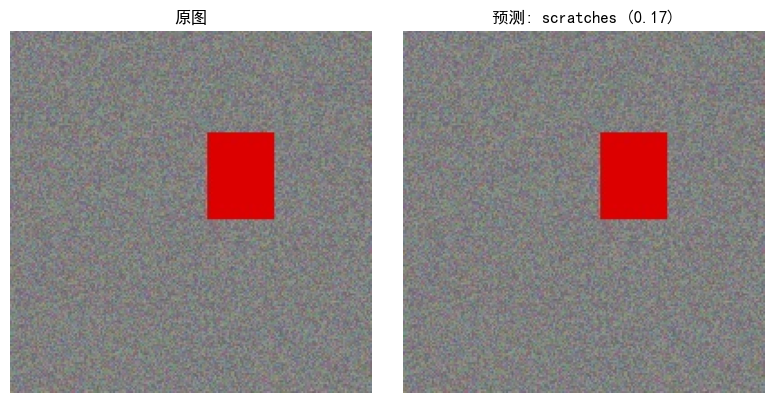

In [8]:
# ===== B7：模型推理与结果可视化 =====
import numpy as np
import cv2
import matplotlib.pyplot as plt
from tensorflow.keras.models import load_model

# 1. 加载训练好的CNN分类模型
cnn = load_model('cnn_neu.h5')

# 2. 读取测试图并预处理(BGR->RGB, 缩放, 归一化, 加批次维)
test_path = val_df.iloc[0]['img_path']   # 从验证集取一张做测试
print('测试图像:', test_path)
img = cv2.imread(test_path)[:, :, ::-1]
x = cv2.resize(img, IMG_SIZE) / 255.0
x = np.expand_dims(x, 0)

# 3. 分类推理:softmax概率 -> argmax取类别
prob = cnn.predict(x)[0]
pred_id = np.argmax(prob)
print(f'预测类别: {CLASS_NAMES[pred_id]}, 置信度: {prob[pred_id]:.2f}')

# 4. (若用U-Net分割)概率图 -> 0.5阈值 -> 二值掩膜
# TODO: U-Net 分割推理被注释未实现，若赛题要求分割需补全
# xs = cv2.resize(img, (128, 128)) / 255.0
# mask = (unet.predict(xs[np.newaxis])[0, :, :, 0] > 0.5).astype('uint8')

# 5. 原图与预测结果对比
fig, ax = plt.subplots(1, 2, figsize=(8, 4))
ax[0].imshow(img); ax[0].set_title('原图'); ax[0].axis('off')
ax[1].imshow(img)
ax[1].set_title(f'预测: {CLASS_NAMES[pred_id]} ({prob[pred_id]:.2f})')
ax[1].axis('off')
plt.tight_layout()
plt.show()

## B8 混淆矩阵分析与模型优化（4分）
**做什么**：收集验证集真实/预测标签 → `confusion_matrix` → seaborn热力图 → 找最易混淆类别对 → 给出优化方向并重训对比。

**记忆点**：对角线=预测正确；非对角线最大值=最易混淆的一对。

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 147ms/step


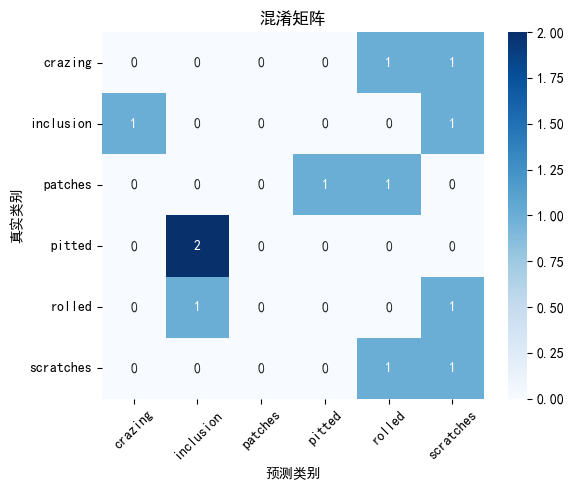

最易混淆: pitted 被误判为 inclusion, 共 2 次
优化方向: 增加卷积层/滤波器、加强数据增强、补充易混类样本后重训


In [9]:
# ===== B8：混淆矩阵分析与模型优化 =====
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix

plt.rcParams['font.sans-serif'] = ['SimHei']
plt.rcParams['axes.unicode_minus'] = False

# 1. 收集验证集真实标签与预测标签
val_gen.reset()
y_true = val_gen.classes
y_pred = np.argmax(cnn.predict(val_gen), axis=1)

# 2. 混淆矩阵热力图
cm = confusion_matrix(y_true, y_pred)
plt.figure(figsize=(6, 5))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=CLASS_NAMES, yticklabels=CLASS_NAMES)
plt.xlabel('预测类别')
plt.ylabel('真实类别')
plt.title('混淆矩阵')
plt.xticks(rotation=45)
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

# 3. 找最易混淆的类别对(非对角线最大值)
off = cm.copy()
np.fill_diagonal(off, 0)
i, j = np.unravel_index(off.argmax(), off.shape)
print(f'最易混淆: {CLASS_NAMES[i]} 被误判为 {CLASS_NAMES[j]}, 共 {off[i, j]} 次')
print('优化方向: 增加卷积层/滤波器、加强数据增强、补充易混类样本后重训')

# 4. 优化示例(按需取消注释):加深一层Conv(128)后重训,再跑一次本cell对比
# model2 = Sequential([...Conv2D(128,(3,3),activation='relu'), MaxPooling2D(), ...])
# model2.compile(...); model2.fit(...); 重新计算混淆矩阵

## B9 工业质检报告生成（4分）
**做什么**：Pandas汇总检测结果 → openpyxl创建工作簿 → 写入表格 → 插入带检测框样例图 → 设置列宽 → 保存 `质检报告.xlsx`。

**记忆点**：`ws.append` 逐行写、`add_image(img,'F2')` 插图、`column_dimensions` 调列宽。

In [10]:
# ===== B9：工业质检报告生成 =====
import os
import cv2
import pandas as pd
import openpyxl
from openpyxl.drawing.image import Image as XLImage

# 0. 准备带检测框的样例图(没有则用验证集第一张画框生成)
if not os.path.exists('result_sample.jpg'):
    r = val_df.iloc[0]
    im = cv2.imread(r.img_path)
    cv2.rectangle(im, (r.xmin, r.ymin), (r.xmax, r.ymax), (0, 0, 255), 2)
    cv2.putText(im, r['class'], (r.xmin, r.ymin - 5),
                cv2.FONT_HERSHEY_SIMPLEX, 0.6, (0, 0, 255), 2)
    cv2.imwrite('result_sample.jpg', im)

# 1. 汇总一批测试图的检测结果(文件名/类别/个数/置信度)
# TODO: report 为硬编码假数据，应替换为 B7/B8 的真实推理结果
report = pd.DataFrame({
    '文件名': ['test1.jpg', 'test2.jpg', 'test3.jpg'],
    '缺陷类别': ['scratches', 'inclusion', 'scratches'],
    '缺陷个数': [2, 1, 3],
    '置信度': [0.95, 0.88, 0.91]
})

# 2. 创建工作簿并写入DataFrame
wb = openpyxl.Workbook()
ws = wb.active
ws.title = '质检结果'
ws.append(list(report.columns))                     # 表头
for row in report.itertuples(index=False):
    ws.append(list(row))

# 3. 在F2单元格插入带检测框的样例图
img = XLImage('result_sample.jpg')
img.width, img.height = 320, 240
ws.add_image(img, 'F2')

# 4. 设置列宽并保存
for col, w in zip('ABCD', [20, 15, 10, 10]):
    ws.column_dimensions[col].width = w
wb.save('质检报告.xlsx')
print('质检报告.xlsx 已生成')
report

质检报告.xlsx 已生成


,文件名,缺陷类别,缺陷个数,置信度
0,test1.jpg,scratches,2,0.95
1,test2.jpg,inclusion,1,0.88
2,test3.jpg,scratches,3,0.91
